In [1]:
import numpy as np
import matplotlib.pyplot as plt

import jlinops 

import sys
sys.path.append("..")


from rsolvers import RIASGKS

# Test problem

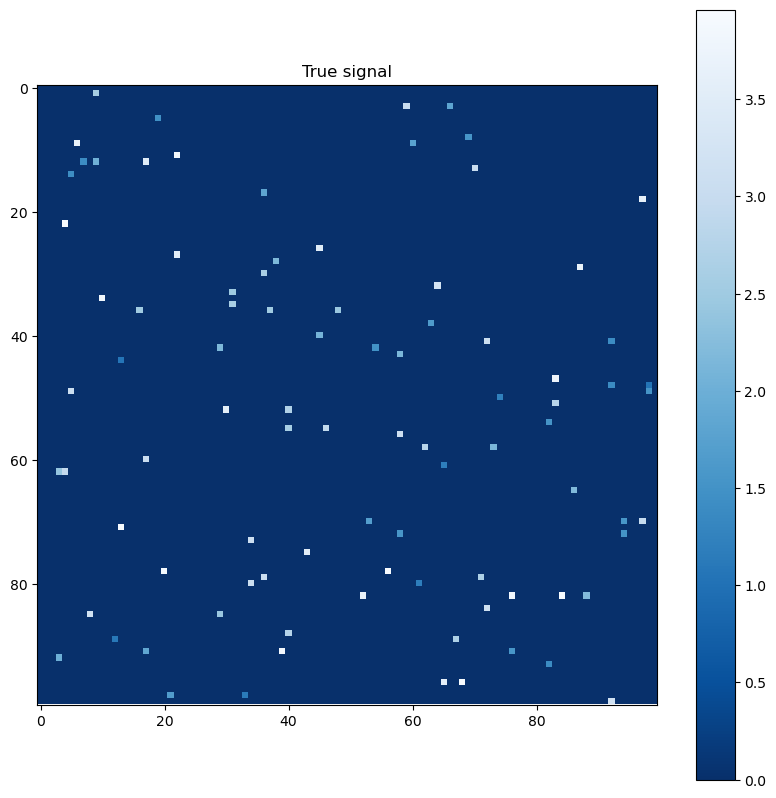

In [2]:

# Set example size
M, N = 100, 100
img_shape = (M,N)

# Draw random image
np.random.seed(1)
p = np.random.binomial(1, 0.01, size=img_shape).astype(np.float64)
q = np.random.uniform(low=1, high=4, size=img_shape).astype(np.float64)
image = p*q

plt.figure(figsize=(10,10))
plt.imshow(image, cmap="Blues_r")
plt.title("True signal")
plt.colorbar()
plt.show()

/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_42835/3596321973.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


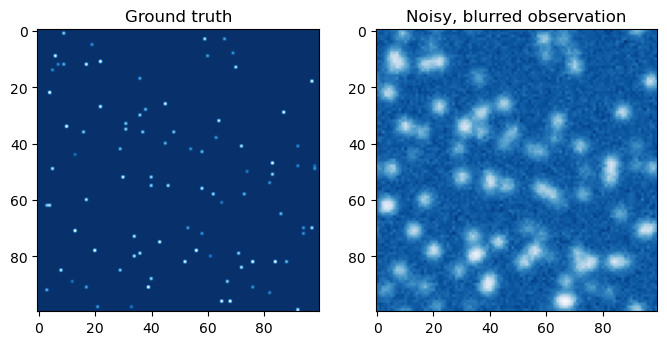

In [6]:

# Make blurring operator
blur_sigma = np.array(2.0).astype(np.float64) # standard deviation of the blur
A = jlinops.Gaussian2DBlurOperator(image.shape, blur_sigma=2)

# Blurred image
blurred_image = A.matvec_shaped(image)

# Add some noise
noise_sigma = 0.01
noise_var = noise_sigma**2
noisy_image = blurred_image + noise_sigma*np.random.normal(size=image.shape)

# Plot
fig, axs = plt.subplots(1, 2, figsize=(8,5))
axs[0].imshow(image, cmap="Blues_r")
axs[0].set_title("Ground truth")
axs[1].imshow(noisy_image, cmap="Blues_r")
axs[1].set_title("Noisy, blurred observation")
fig.show()

In [7]:
#L = jlinops.Neumann2D(image.shape)
L = jlinops.IdentityOperator((M*N, M*N))

# Comparison with convex parameters

In [8]:
# TRIPs-Py methods are dp and gcv. The rest I have added. I believe dp is the same as dp3, except uses the GSVD in the formulation of the method whereas dp3 avoids using a GSVD.
methods = ["dp", "dp2", "dp3", "mgcv", "gcv", "matlab_gcv", "mgcv_no_whitening", "gcv_no_whitening", "matlab_gcv_no_whitening" ]
print(f"Number of methods to compare: {len(methods)}")

Number of methods to compare: 9


In [11]:
# Set problem parameters
n_iters = 1000
hyperpr_r = 1
hyperpr_beta = 1.5 + 1e-3
kmin = 5
kmax = 15

# Build a dictionary containg solvers and solver results
comp_dct = {}

# Iterate over methods
for method in methods:
    print(f"Started method: {method}")

    # Build solver
    if (method == "mgcv_no_whitening") or (method == "gcv_no_whitening") or (method == "matlab_gcv_no_whitening"):
        gksias_solver = RIASGKS(A, L, noisy_image.flatten(), noise_var=None)
    else:
        gksias_solver = RIASGKS(A, L, noisy_image.flatten(), noise_var=noise_var)

    # Processing for regparam method
    if (method == "mgcv_no_whitening"):
        regparam = "mgcv"
    elif (method == "gcv_no_whitening"):
        regparam = "gcv"
    elif (method == "matlab_gcv_no_whitening"):
        regparam = "matlab_gcv"
    else:
        regparam = method

    try:
        # Run the solver
        data = gksias_solver.solve(n_iter=n_iters, kmin=kmin, kmax=kmax, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=image.flatten(), regparam=regparam)
    except:
        pass
    
    # Put results into dict
    comp_dct[method] = data

Started method: dp


Started method: dp2


 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
Started method: dp3
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/comparisons/../regparam_selection.py:170: RuntimeWarning: invalid value encountered in sqrt
  xbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=None  )


 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
Started method: mgcv
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/comparisons/../regparam_selection.py:313: RuntimeWarning: overflow encountered in scalar power
  term1 = -(2/(beta**4))*np.dot( QinvLtLxbeta, L.T @ Lxbeta )
/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/comparisons/../regparam_selection.py:315: RuntimeWarning: overflow encountered in scalar power
  term2 = (2/(beta**4))*np.dot(QinvLtLxbeta, AtAQinvLtLxbeta )
/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/comparisons/../regparam_selection.py:317: RuntimeWarning: overflow encountered in scalar power
  term3 =  (4/(beta**4))*np.dot( L @ QinvAtAxbeta, L @ QinvLtLxbeta )
/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/comparisons/../regparam_selection.py:318: RuntimeWarning: overflow encountered in scalar power
  term4 = -(2/(beta**4))*np.dot( L @ xbeta, L @ QinvLtLxbeta )
/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/comparisons/../regparam_selection.py:319: RuntimeWarning: overflow encountered in scalar power
  term5 = -(4/(beta**3))*np.dot(

Started method: gcv


/Users/jonathanlindbloom/Github/trips-py/trips/utilities/reg_param/gcv.py:43: LinAlgWarning: Ill-conditioned matrix (rcond=1.91283e-18): result may not be accurate.
  inverted = la.solve( ( R_A_2 + reg_param * R_L_2), (R_A.T @ Q_A.T @ b) )
/Users/jonathanlindbloom/Github/trips-py/trips/utilities/reg_param/gcv.py:67: LinAlgWarning: Ill-conditioned matrix (rcond=1.91283e-18): result may not be accurate.
  inverted = la.solve( ( R_A_2 + reg_param * R_L_2), R_A.T )
/Users/jonathanlindbloom/Github/trips-py/trips/utilities/reg_param/gcv.py:43: LinAlgWarning: Ill-conditioned matrix (rcond=2.94601e-17): result may not be accurate.
  inverted = la.solve( ( R_A_2 + reg_param * R_L_2), (R_A.T @ Q_A.T @ b) )
/Users/jonathanlindbloom/Github/trips-py/trips/utilities/reg_param/gcv.py:67: LinAlgWarning: Ill-conditioned matrix (rcond=2.94601e-17): result may not be accurate.
  inverted = la.solve( ( R_A_2 + reg_param * R_L_2), R_A.T )
/Users/jonathanlindbloom/Github/trips-py/trips/utilities/reg_param/g

Started method: matlab_gcv


In [ ]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(data["rre_history"], label=method)

plt.legend(loc="upper right")
plt.title("RRE history")
plt.show()

In [ ]:
plt.figure(figsize=(13,8))

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(data["lambda_history"], label=method)

plt.legend(loc="upper right")
plt.title("History of $\\lambda$")
plt.show()